# TV1 - Kiểm tra, chuẩn hóa và phân tích dữ liệu

Notebook chạy trên **7 CSV thật trong `data/raw/`**. Phần lượng bán được phân tích từ toàn bộ train. Không huấn luyện hay lựa chọn mô hình trong phần việc TV1.

Mục tiêu bàn giao: chất lượng dữ liệu, cách ghép bảng, các phát hiện EDA và dữ liệu nền có thể tái tạo. CSV gốc giữ nguyên. Các tổng `sales` giữa nhóm hàng chỉ là tổng kỹ thuật của biến mục tiêu, không phải doanh thu hay một đại lượng vật lý đồng nhất.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "store_sales").is_dir() and (p / "data" / "raw").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from store_sales.data import load_raw_data, quality_report
from store_sales.eda import analyze, create_figures, write_eda_report

RAW_DIR = ROOT / "data" / "raw"
FIGURE_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "reports"
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)


## 1. Đọc và kiểm tra các bảng

Đọc dữ liệu bằng cùng hàm dùng trong script chuẩn hóa. Giữ cột ngày ở kiểu ngày và nhóm hàng ở kiểu category để giảm bộ nhớ. Các kiểm tra xem xét khóa, ID, khoảng ngày, giá trị thiếu, dữ liệu phụ và khả năng ghép bảng.


In [2]:
tables = load_raw_data(RAW_DIR)
quality = quality_report(tables)
file_overview = pd.DataFrame([
    {"file": name + ".csv", "rows": info["rows"], "columns": len(info["columns"]),
     "null_cells": sum(info["nulls"].values()), "duplicate_rows": info["duplicate_rows"]}
    for name, info in quality["files"].items()
])
display(file_overview)
display(pd.DataFrame(quality["partitions"]).T)
display(pd.DataFrame({"column": tables["train"].columns,
                      "dtype": [str(t) for t in tables["train"].dtypes]}))


,file,rows,columns,null_cells,duplicate_rows
0,train.csv,3000888,6,0,0
1,test.csv,28512,5,0,0
2,stores.csv,54,5,0,0
3,oil.csv,1218,2,43,0
4,transactions.csv,83488,3,0,0
5,holidays_events.csv,350,6,0,0
6,sample_submission.csv,28512,2,0,0


,rows,date_min,date_max,observed_days,missing_dates,stores,...,daily_rows_max,days_with_incomplete_pair_grid,null_required_values,zero_sales_rows,zero_sales_fraction,fractional_sales_rows
train,3000888,2013-01-01,2017-08-15,1684,"[2013-12-25, 2014-12-25, 2015-12-25, 2016-12-25]",54,...,1782,0,0,939130,0.312951,462113
test,28512,2017-08-16,2017-08-31,16,[],54,...,1782,0,0,NaN,NaN,NaN


,column,dtype
0,id,int64
1,date,datetime64[us]
2,store_nbr,int16
3,family,category
4,sales,float64
5,onpromotion,int32


In [3]:
train = tables["train"]
test = tables["test"]
assert not train.duplicated(["date", "store_nbr", "family"]).any()
assert not test.duplicated(["date", "store_nbr", "family"]).any()
assert test["id"].reset_index(drop=True).equals(tables["sample_submission"]["id"].reset_index(drop=True))
assert train["date"].max() < test["date"].min()
print("Khóa không trùng; ID test khớp sample_submission; train đứng trước test.")
print("Ngày thiếu hoàn toàn trong train:", quality["partitions"]["train"]["missing_dates"])
display(pd.Series(quality["auxiliary"], name="Kiểm tra bảng phụ").to_frame())


Khóa không trùng; ID test khớp sample_submission; train đứng trước test.
Ngày thiếu hoàn toàn trong train: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


,Kiểm tra bảng phụ
holiday_unique_dates,312
holiday_max_events_per_date,4
holiday_duplicate_date_store_warning,Aggregate events by date and applicable store before merge.
holiday_unmatched_locality_rows,[]
oil_missing_values,43
oil_duplicate_dates,0
oil_coverage,"{'train': {'sales_dates': 1684, 'dates_without_oil_row': 481, 'dates_with_missing_oil_..."
transactions_date_max,2017-08-15
transactions_available_during_test,False
transactions_duplicate_keys,0


## 2. Phân bố, khác biệt giữa nhóm hàng và khuyến mãi

Số 0 trong nguồn là một nhãn đã quan sát. Ngày không có dòng dữ liệu là thiếu quan sát. Không đồng nhất hai trường hợp này; cũng không suy ra nguyên nhân đóng cửa/hết hàng từ số 0.

`onpromotion` là số mặt hàng trong nhóm đang được khuyến mãi. So sánh lượng bán theo khuyến mãi dưới đây là liên hệ quan sát, còn chịu ảnh hưởng nhóm hàng, cửa hàng và thời gian.


In [4]:
analysis = analyze(tables)
display(train["sales"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).to_frame())
display(pd.Series(analysis["sales"], name="Thống kê sales").to_frame())
display(pd.DataFrame(analysis["family_summary"]).head(12))
display(pd.DataFrame(analysis["promotion_overall"]))
display(pd.DataFrame(analysis["store_summary"]).head(10))


,sales
count,3.000888e+06
mean,3.577757e+02
std,1.101998e+03
min,0.000000e+00
25%,0.000000e+00
50%,1.100000e+01
75%,1.958473e+02
95%,1.965000e+03
99%,5.507000e+03
max,1.247170e+05


,Thống kê sales
zero_rows,939130.000000
zero_fraction,0.312951
fractional_rows,462113.000000
mean,357.775749
median,11.000000
p25,0.000000
p75,195.847250
p95,1965.000000
p99,5507.000000
max,124717.000000


,family,rows,total_sales,mean_sales,zero_rate
0,GROCERY I,90936,3.434627e+08,3776.972100,0.080628
1,BEVERAGES,90936,2.169545e+08,2385.793151,0.080617
2,PRODUCE,90936,1.227047e+08,1349.352123,0.283551
3,CLEANING,90936,9.752129e+07,1072.416744,0.080617
4,DAIRY,90936,6.448771e+07,709.154889,0.080617
5,BREAD/BAKERY,90936,4.213395e+07,463.336254,0.080606
6,POULTRY,90936,3.187600e+07,350.532292,0.080760
7,MEATS,90936,3.108647e+07,341.849965,0.080617
8,PERSONAL CARE,90936,2.459205e+07,270.432513,0.080650
9,DELI,90936,2.411032e+07,265.135067,0.080617


,promoted,rows,mean_sales,median_sales
0,False,2389559,158.246681,3.0
1,True,611329,1137.693730,373.0


,store_nbr,rows,total_sales,positive_rows,observed_days
0,44,55572,6.208755e+07,45598,1684
1,45,55572,5.449801e+07,44814,1684
2,47,55572,5.094831e+07,45039,1684
3,3,55572,5.048191e+07,45491,1684
4,49,55572,4.342010e+07,44820,1684
5,46,55572,4.189606e+07,44835,1684
6,48,55572,3.593313e+07,43723,1684
7,51,55572,3.291149e+07,44390,1684
8,8,55572,3.049429e+07,44496,1684
9,50,55572,2.865302e+07,44095,1684


## 3. Biểu đồ EDA

Sáu biểu đồ xem xu hướng theo ngày, khác biệt theo thứ, phân bố trên thang log, quy mô và tỷ lệ số 0 theo nhóm hàng, liên hệ với khuyến mãi, cùng các chuỗi có quy mô khác nhau. Mọi dòng train được giữ để tính thống kê; không loại ngoại lệ hoặc điền nhãn thiếu trong EDA.


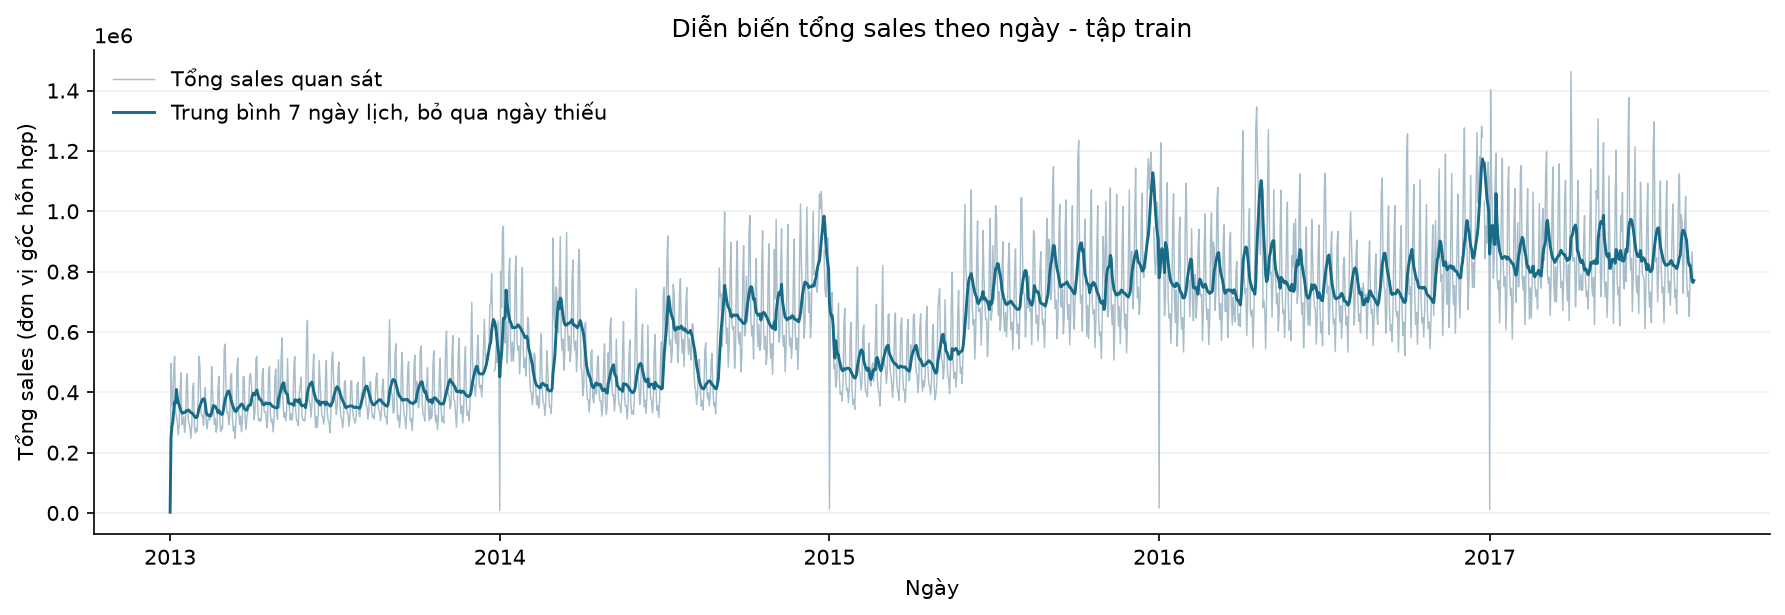

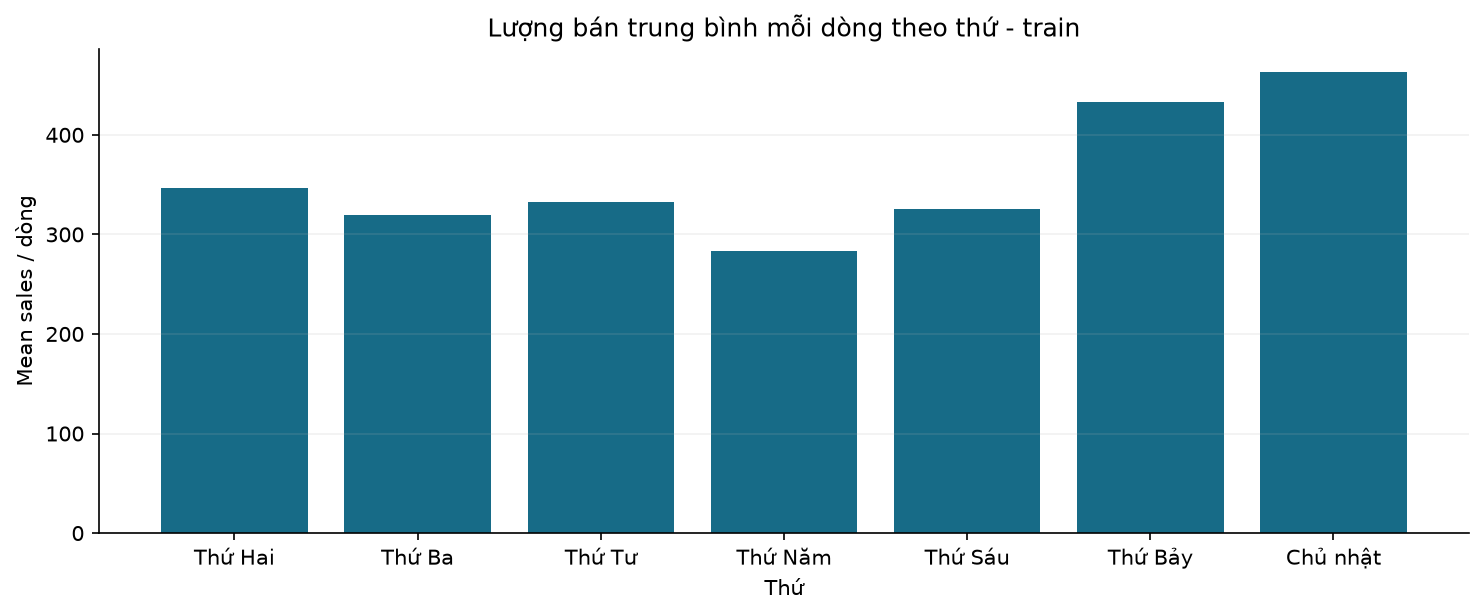

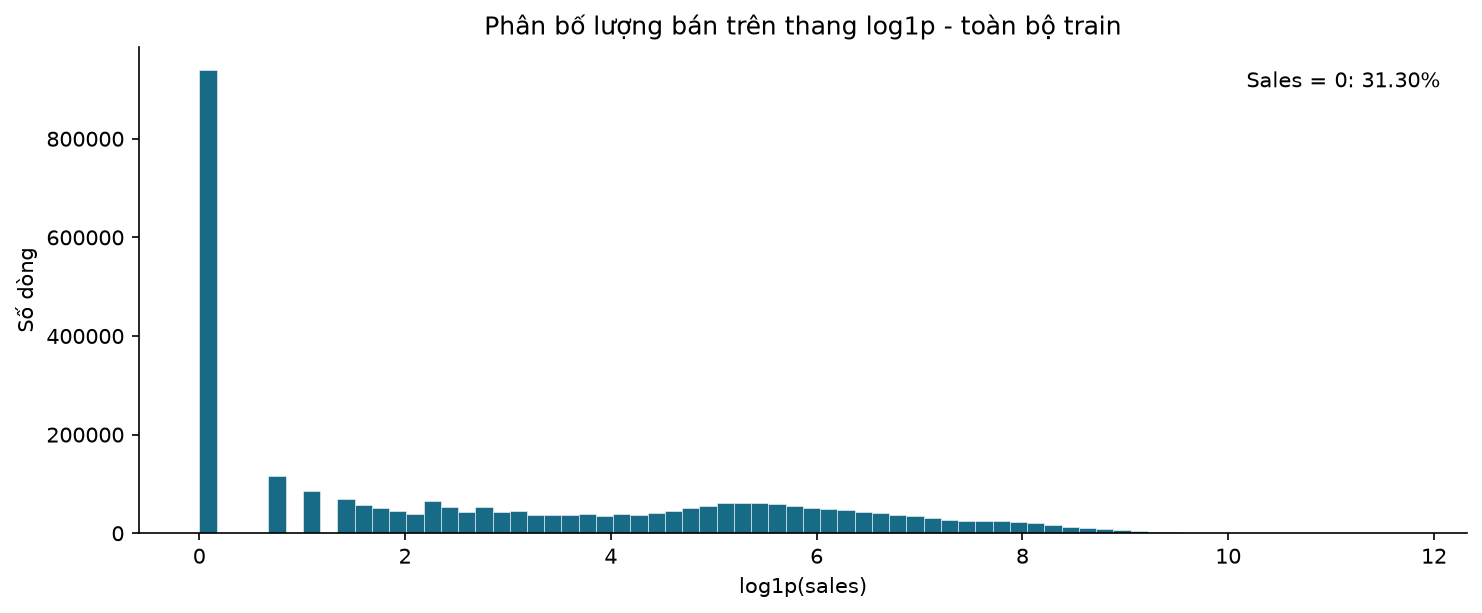

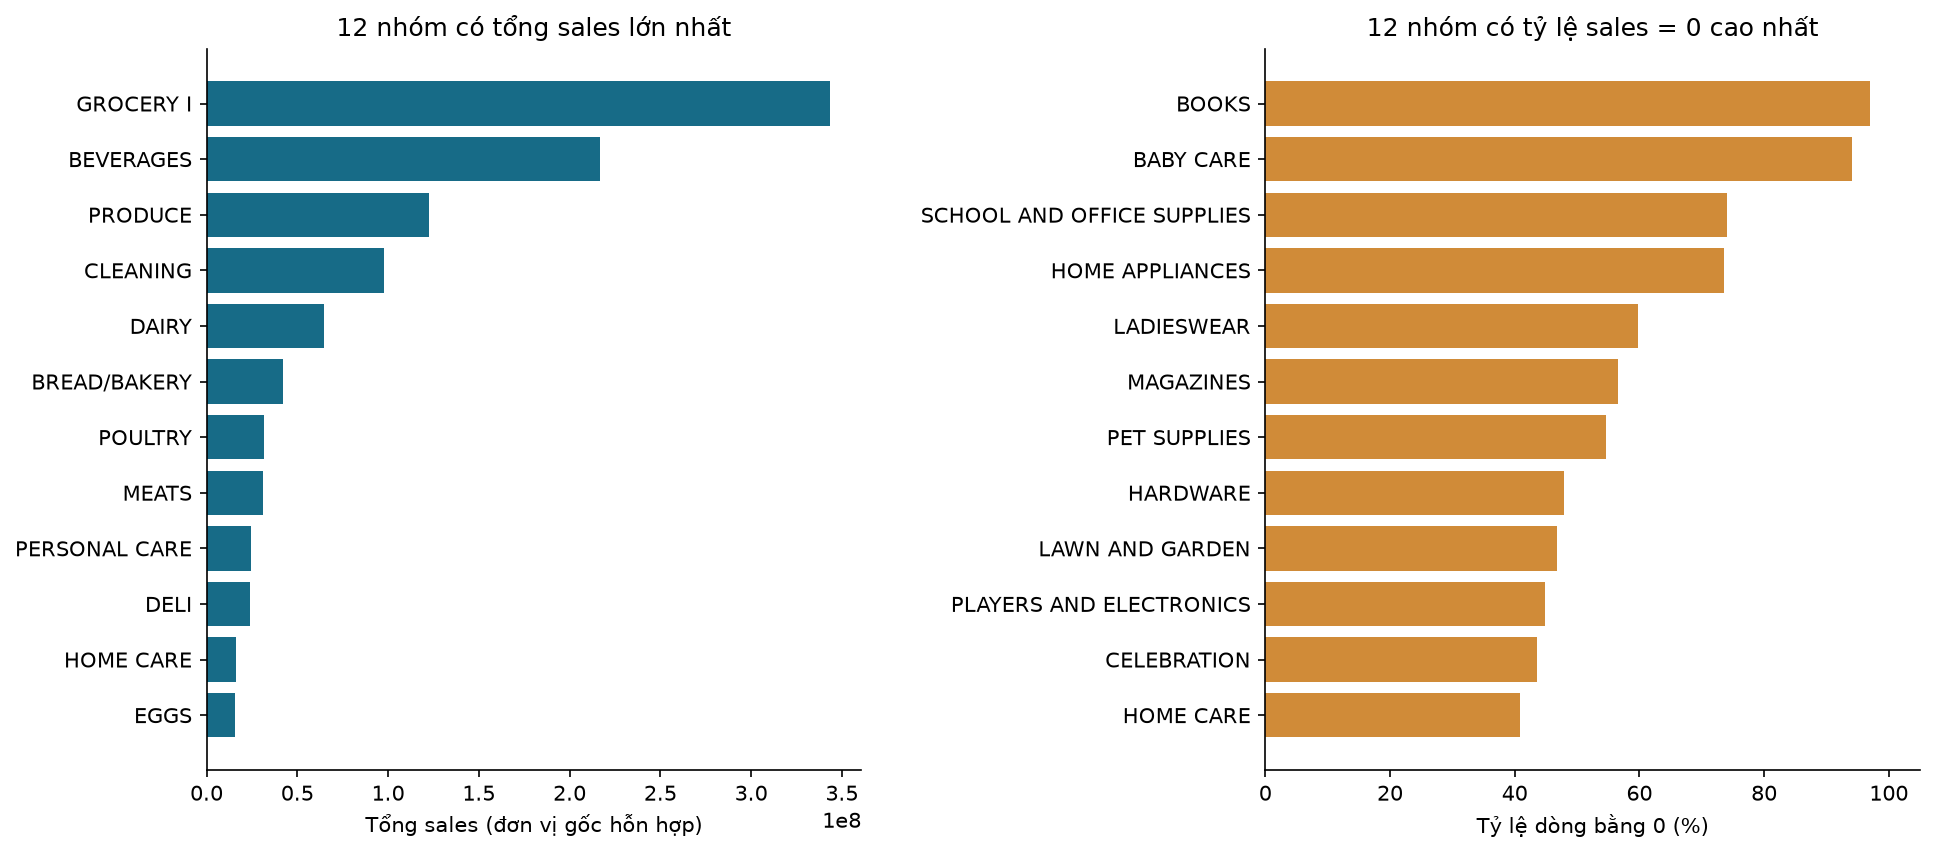

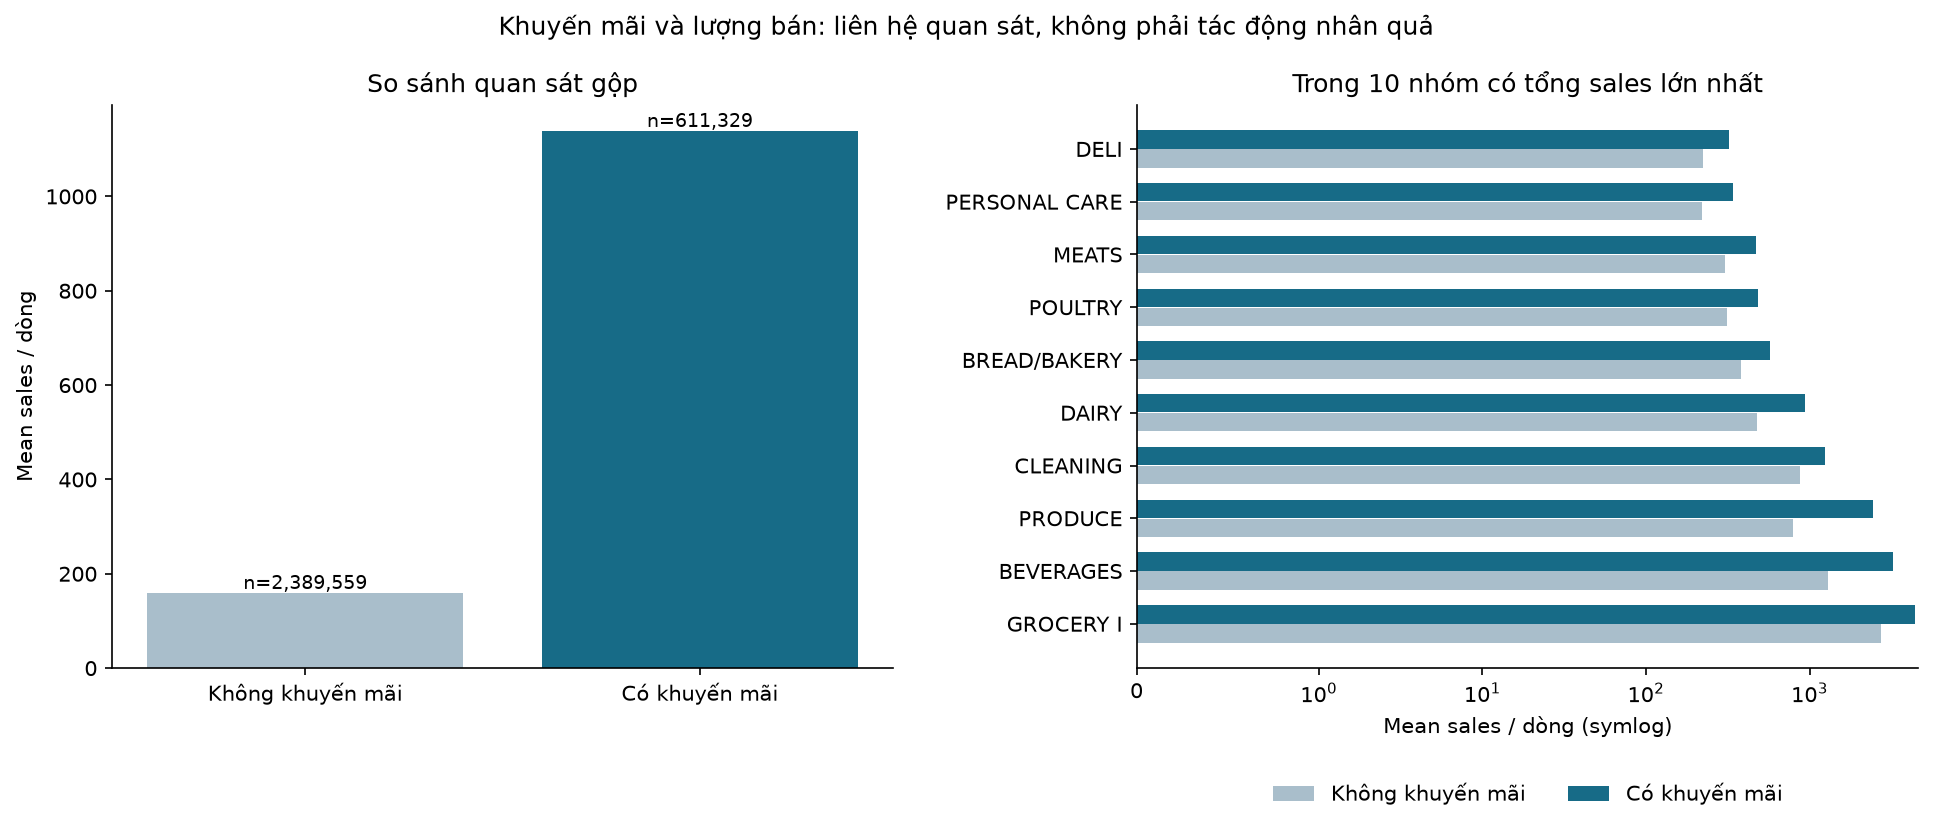

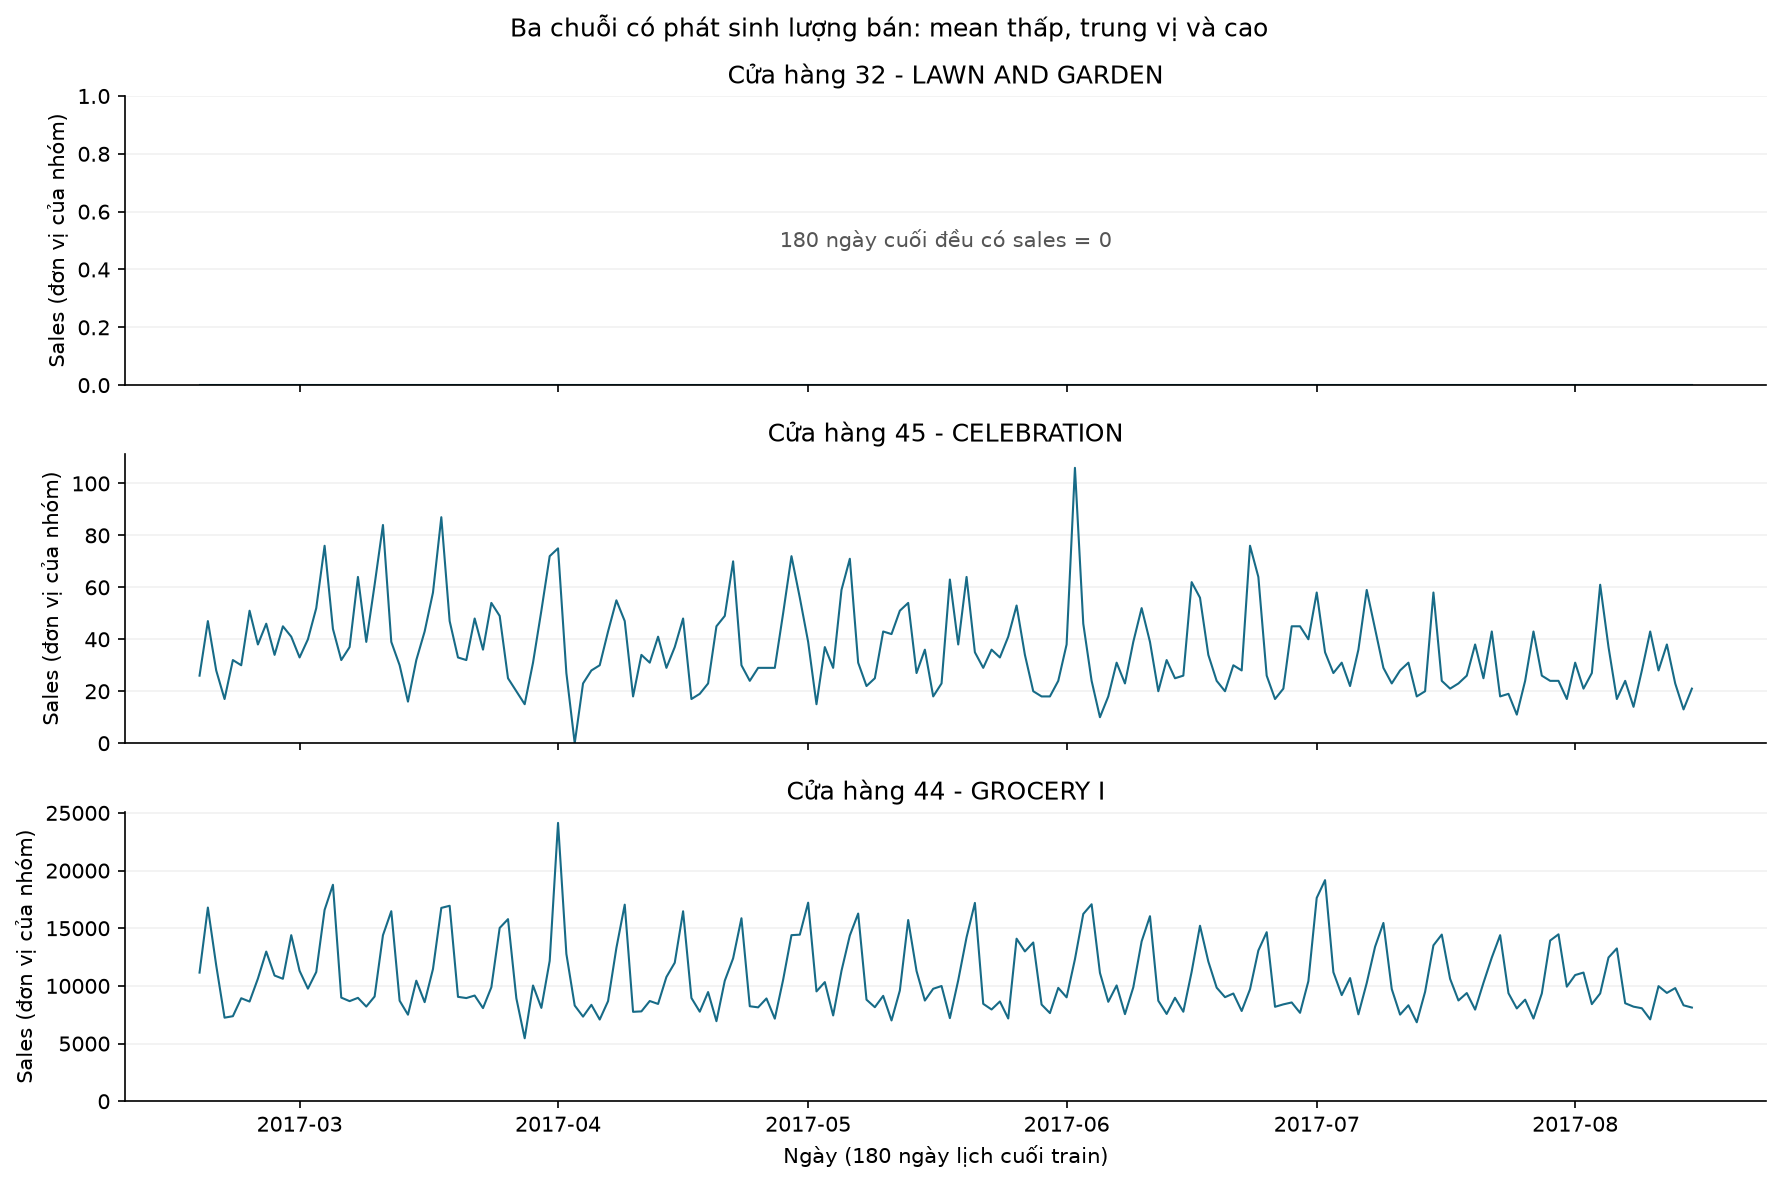

In [5]:
figure_paths = create_figures(tables, analysis, FIGURE_DIR)
for path in figure_paths:
    display(Image(filename=str(path), width=1050))


## 4. Nhận xét tính từ dữ liệu thật

Nhận xét được sinh từ cùng thống kê và được lưu vào `reports/eda_report.md`, tránh chép số liệu khác với lần chạy. Bảng đầy đủ từng nhóm hàng và biểu đồ cũng nằm trong báo cáo đó.


In [6]:
write_eda_report(analysis, figure_paths, REPORT_DIR)
report_text = (REPORT_DIR / "eda_report.md").read_text(encoding="utf-8")
display(Markdown(report_text.split("## Bảng tóm tắt nhóm hàng")[0]))


# EDA - Phần việc TV1

Nguồn: 7 CSV tại `data/raw/`. Các thống kê lượng bán chỉ dùng `train.csv`; không có mô hình được huấn luyện trong bước này.

## Phạm vi dữ liệu

- Train: **3,000,888 dòng**, 2013-01-01 đến 2017-08-15.
- Test: **28,512 dòng**, 16 ngày, 2017-08-16 đến 2017-08-31.
- Có **54 cửa hàng, 33 nhóm hàng, 1,782 chuỗi cửa hàng-nhóm hàng**.
- Các ngày không xuất hiện trong train: 2013-12-25, 2014-12-25, 2015-12-25, 2016-12-25. Ngày thiếu không được điền thành sales = 0.

## Các phát hiện

1. **Nhiều số 0:** 939,130 dòng (31.30%) có sales = 0. Nhóm BOOKS có tỷ lệ cao nhất (96.96%). Không thể chỉ từ sales = 0 kết luận hết hàng, đóng cửa hay không có nhu cầu.
2. **Phân bố lệch:** mean 357.78, median 11.00, p95 1,965.00, p99 5,507.00, max 124,717.00. Cần xem thêm thang log để quan sát cả giá trị nhỏ và lớn; EDA không loại các giá trị lớn này.
3. **Khác biệt theo thứ:** Chủ nhật có mean sales/dòng cao nhất (463.09); Thứ Năm thấp nhất (283.54) khi gộp toàn bộ train. Kết quả mô tả không bảo đảm áp dụng giống nhau cho từng cửa hàng/nhóm hàng hoặc tương lai.
4. **Khác biệt quy mô nhóm hàng:** nhóm có tổng sales lớn nhất là GROCERY I. Tổng này cộng đại lượng có thể khác đơn vị giữa các nhóm, nên không diễn giải thành doanh thu hoặc so sánh giá trị kinh tế.
5. **Đơn vị bán có thể lẻ:** có 462,113 dòng sales là số thập phân; giữ kiểu số thực, không làm tròn nhãn thành số nguyên.
6. **Liên hệ với khuyến mãi:** mean sales/dòng khi onpromotion > 0 là 1,137.69 (n=611,329); khi bằng 0 là 158.25 (n=2,389,559). Biểu đồ bổ sung so sánh trong từng family. Đây không phải ước lượng tác động: còn khác biệt thời gian, cửa hàng, nhu cầu và cách chọn khuyến mãi.



## 5. Quy tắc tiền xử lý và bảng nền bàn giao

- Giữ `id`, khóa `(date, store_nbr, family)` và nhãn train gốc. Test giữ `sales = NaN`, `is_test = True`, `sales_observed = False`.
- Ghép stores theo nhiều-một. Tổng hợp ngày lễ theo ngày/cửa hàng và phạm vi National/Regional/Local trước khi ghép để không nhân bản dòng.
- Ngày gốc có `transferred = True` được phân biệt với ngày nghỉ thực tế `Transfer`. Giữ riêng cờ ngày làm bù và sự kiện.
- Tạo đặc trưng lịch không dùng nhãn: ngày/tháng/năm, thứ, cuối tuần và ngày nhận lương theo quy ước dữ liệu.
- Chưa tự điền giá dầu hoặc ghép giao dịch tương lai. Các bảng nguồn vẫn được giữ để thành viên khác quyết định cách sử dụng.
- Chưa tạo lag, chuẩn hóa theo thống kê nhãn hay chọn mô hình. Khi dự báo, thông tin sales lịch sử chỉ được dùng trước mốc dự báo.

Lệnh `python scripts/prepare_data.py` tạo bảng nền và báo cáo chất lượng. Notebook không nạp toàn bộ bảng nền lần nữa chỉ để kiểm tra số dòng; phần dưới đọc metadata Parquet và manifest.


In [7]:
panel_path = ROOT / "data" / "processed" / "base_panel.parquet"
manifest_path = REPORT_DIR / "data_manifest.json"
if panel_path.exists() and manifest_path.exists():
    import pyarrow.parquet as pq
    panel_file = pq.ParquetFile(panel_path)
    assert panel_file.metadata.num_rows == len(train) + len(test)
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    display(pd.DataFrame({"column": panel_file.schema_arrow.names,
                          "dtype": [str(f.type) for f in panel_file.schema_arrow]}))
    print("Bảng nền có", f"{panel_file.metadata.num_rows:,}", "dòng; không nhân bản dòng gốc.")
    print("Manifest đã lưu checksum của", len(manifest["raw_files"]), "CSV.")
else:
    print("Chạy python scripts/prepare_data.py để tạo bảng nền và manifest trước khi bàn giao.")


,column,dtype
0,id,int64
1,date,timestamp[us]
2,store_nbr,int16
3,family,"dictionary<values=string, indices=int8, ordered=0>"
4,sales,double
5,onpromotion,int32
6,is_test,bool
7,sales_observed,bool
8,city,"dictionary<values=string, indices=int8, ordered=0>"
9,state,"dictionary<values=string, indices=int8, ordered=0>"


Bảng nền có 3,029,400 dòng; không nhân bản dòng gốc.
Manifest đã lưu checksum của 7 CSV.


## 6. Sản phẩm bàn giao của TV1

| Tệp/thư mục | Mục đích |
|---|---|
| `data/processed/base_panel.parquet` | Dữ liệu nền với cửa hàng, lịch và cờ ngày lễ; không có đặc trưng sales tương lai |
| `reports/data_quality.md` và `.json` | Kết quả kiểm tra 7 nguồn và những vấn đề cần lưu ý |
| `reports/data_manifest.json` | Checksum dữ liệu, schema và thông tin tái lập |
| `reports/eda_report.md` và `eda_summary.json` | Nhận xét và thống kê thực tế |
| `outputs/figures/` | Sáu ảnh dùng trong thảo luận và slide phần dữ liệu |
| `docs/data_dictionary.md` và `docs/TV1.md` | Ý nghĩa cột, quy tắc xử lý và cách dùng tiếp |

Chạy lại: `python scripts/prepare_data.py` rồi `python scripts/run_eda.py`, hoặc chạy notebook từ đầu đến cuối sau bước chuẩn hóa. Các thành viên khác tự chọn mô hình và thống nhất cách kiểm định; EDA toàn bộ train ở đây phục vụ mô tả, không thay thế kiểm định dự báo.
